In [1]:
# Fashion MNIST 데이터셋 불러오기
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical

(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

print('x_train_full shape:', x_train_full.shape)  # (60000, 28, 28)
print('x_test shape:', x_test.shape)               # (10000, 28, 28)

4422102/4422102 [==============================] - 1s 0us/step
x_train_full shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)


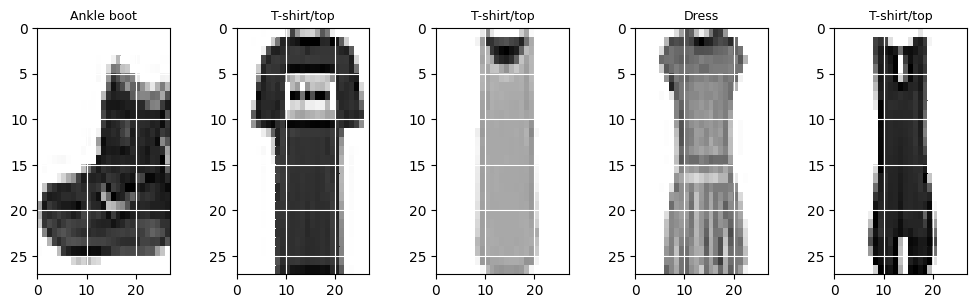

In [2]:
# 데이터셋 클래스 이름
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 샘플 이미지 시각화
plt.figure(figsize=(12, 3.2))
plt.subplots_adjust(wspace=0.5)
plt.gray()
for id in range(5):
    plt.subplot(1, 5, id + 1)
    img = x_train_full[id, :, :]
    plt.pcolor(255 - img)
    plt.title(class_names[y_train_full[id]], fontsize=9)
    plt.xlim(0, 27)
    plt.ylim(27, 0)
    plt.grid('on', color='white')
plt.show()

In [3]:
# 데이터 분할: 55,000 훈련 / 5,000 검증 / 10,000 테스트
num_classes = 10

# 훈련/검증 분할 (55000 / 5000)
x_train = x_train_full[:55000]
y_train = y_train_full[:55000]
x_val = x_train_full[55000:]
y_val = y_train_full[55000:]

# CNN 입력 형태로 변환: (N, 28, 28, 1)
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255
x_val   = x_val.reshape(-1, 28, 28, 1).astype('float32') / 255
x_test  = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255

# One-hot 인코딩
y_train = to_categorical(y_train, num_classes)
y_val   = to_categorical(y_val, num_classes)
y_test  = to_categorical(y_test, num_classes)

print('x_train shape:', x_train.shape)  # (55000, 28, 28, 1)
print('x_val shape:  ', x_val.shape)    # (5000, 28, 28, 1)
print('x_test shape: ', x_test.shape)   # (10000, 28, 28, 1)

x_train shape: (55000, 28, 28, 1)
x_val shape:   (5000, 28, 28, 1)
x_test shape:  (10000, 28, 28, 1)


In [4]:
# CNN 모델 구현
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

np.random.seed(1)

model = Sequential()

# 합성곱층 1: 32개 필터, (3,3) 커널, ReLU 활성화
model.add(Conv2D(32, (3, 3), padding='same', input_shape=(28, 28, 1), activation='relu'))
# 합성곱층 2: 64개 필터
model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
# 최대 풀링층: 2×2
model.add(MaxPooling2D(pool_size=(2, 2)))
# Dropout
model.add(Dropout(0.25))
# Flatten
model.add(Flatten())
# 완전 연결층: 128개 뉴런
model.add(Dense(128, activation='relu'))
# Dropout
model.add(Dropout(0.5))
# 출력층: 10개 클래스, 소프트맥스
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])

In [5]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 28, 28, 64)        18496     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 64)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 14, 14, 64)        0         
                                                                 
 flatten (Flatten)           (None, 12544)             0         
                                                                 
 dense (Dense)               (None, 128)               1605760   
                                                        

In [6]:
# 학습
import time
start_time = time.time()

history = model.fit(
    x_train, y_train,
    batch_size=1000,
    epochs=30,
    verbose=1,
    validation_data=(x_val, y_val)
)

print("Computation time: {:.3f} sec".format(time.time() - start_time))

Epoch 1/30


2026-06-20 15:30:21.858259: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


55/55 [==============================] - 57s 1s/step - loss: 0.7722 - accuracy: 0.7299 - val_loss: 0.4046 - val_accuracy: 0.8494
Epoch 2/30
55/55 [==============================] - 58s 1s/step - loss: 0.4258 - accuracy: 0.8517 - val_loss: 0.3291 - val_accuracy: 0.8770
Epoch 3/30
55/55 [==============================] - 61s 1s/step - loss: 0.3598 - accuracy: 0.8749 - val_loss: 0.2935 - val_accuracy: 0.8910
Epoch 4/30
55/55 [==============================] - 61s 1s/step - loss: 0.3247 - accuracy: 0.8861 - val_loss: 0.2646 - val_accuracy: 0.9004
Epoch 5/30
55/55 [==============================] - 62s 1s/step - loss: 0.2973 - accuracy: 0.8934 - val_loss: 0.2709 - val_accuracy: 0.8958
Epoch 6/30
55/55 [==============================] - 66s 1s/step - loss: 0.2770 - accuracy: 0.9017 - val_loss: 0.2446 - val_accuracy: 0.9062
Epoch 7/30
55/55 [==============================] - 68s 1s/step - loss: 0.2596 - accuracy: 0.9076 - val_loss: 0.2459 - val_accuracy: 0.9072
Epoch 8/30
55/55 [=============

In [7]:
# 테스트 데이터로 평가
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:    ", score[0])
print("Test accuracy:", score[1])

Test loss:     0.23088151216506958
Test accuracy: 0.9283000230789185


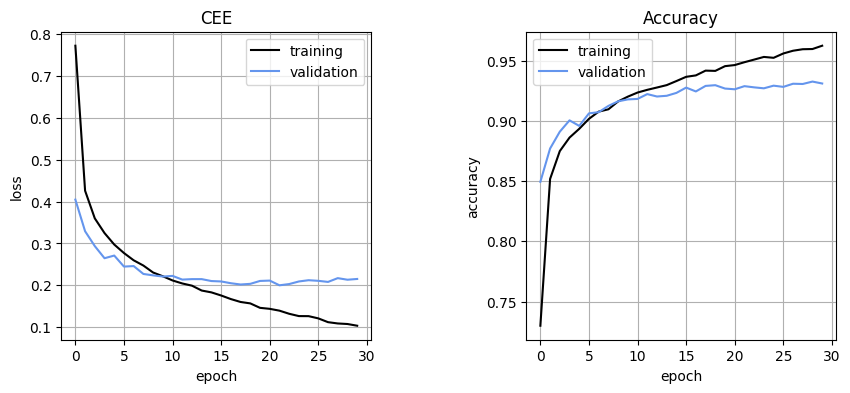

In [8]:
# 학습 곡선 시각화
plt.figure(1, figsize=(10, 4))
plt.subplots_adjust(wspace=0.5)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='training', color='black')
plt.plot(history.history['val_loss'], label='validation', color='cornflowerblue')
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('CEE')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='training', color='black')
plt.plot(history.history['val_accuracy'], label='validation', color='cornflowerblue')
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Accuracy')
plt.show()

313/313 [==============================] - 2s 6ms/step
Total wrong answer: 7 / 96


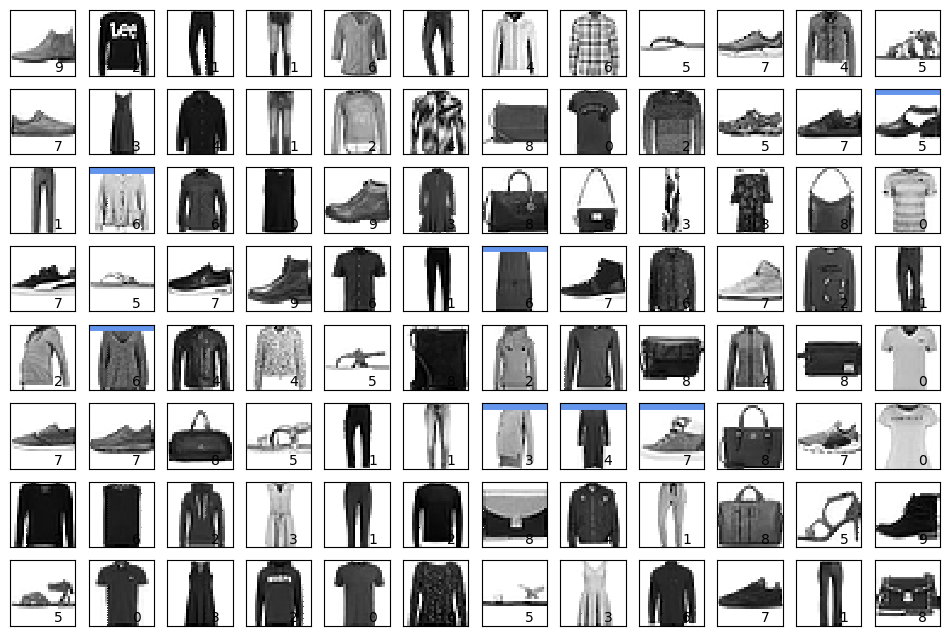

In [9]:
# 테스트 데이터 예측 결과 시각화
def show_prediction():
    n_show = 96
    y = model.predict(x_test)
    plt.figure(2, figsize=(12, 8))
    plt.gray()
    wrong_answer = 0
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :, :, 0]
        plt.pcolor(1 - x)
        prediction = np.argmax(y[i, :])
        plt.text(18, 25.5, "%d" % prediction, fontsize=10)
        if prediction != np.argmax(y_test[i, :]):
            plt.plot([0, 27], [1, 1], color='cornflowerblue', linewidth=5)
            wrong_answer += 1
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {:d} / 96".format(wrong_answer))

show_prediction()
plt.show()